![logo](https://climate.copernicus.eu/sites/default/files/2025-03/logoline_c3s.png)

# Climatology Analysis of Sea Surface Temperature (SST) and Ice Surface Temperature (IST) Satellite Observations

[![binder](https://mybinder.org/badge.svg)](https://mybinder.org/v2/gh/ecmwf-training/c3s-training-submodule-sat-obs-ocean/develop?labpath=satellite-sst-and-ist-climatology-analysis.ipynb)
[![kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/ecmwf-training/c3s-training-submodule-sat-obs-ocean/blob/develop/satellite-sst-and-ist-climatology-analysis.ipynb)
[![colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ecmwf-training/c3s-training-submodule-sat-obs-ocean/blob/develop/satellite-sst-and-ist-climatology-analysis.ipynb)

:::{note}
This notebook can be run on free online platforms, such as Binder, Kaggle and Colab, or they can be accessed from GitHub. The links to run this notebook in these environments are provided here, but please note they are not supported by ECMWF.
:::

**Last updated:** 2026-10-27

Sea Surface Temperature (SST) and sea Ice Surface Temperature (IST) are Essential Climate Variables. Together they influence many parts of the Earth system: they drive weather patterns and extreme events such as hurricanes and cyclones, contribute to ocean circulation, and shape marine ecosystems, polar climate, global albedo and ocean heat exchange. Computing climatologies, i.e. long-term averages representative of the conditions over at least a few decades, is a key step in turning the raw data into actionable information.

This tutorial introduces the [Combined sea surface and sea ice surface temperature data derived from satellite observations](https://cds.climate.copernicus.eu/datasets/satellite-ist-sst-global?tab=overview) on the C3S Climate Data Store (CDS). You will explore a single daily file, compute a 1991-2020 climatology of surface temperature from monthly files, and map the anomaly of 2024 with respect to that climatology.

The dataset consists of gap-free (Level 4) daily and monthly fields on a global 0.05° grid, provided as two sequential records:

* a Climate Data Record (CDR) covering 1982-2021, and
* an Interim Climate Data Record (ICDR) extending the record from 2022 onwards.

For further information, see the [product user guide and specification](https://dast.copernicus-climate.eu/documents/satellite-ist-sst-global/WP2-FDDP-SSTv1.0-PUGS-v1.1_Final-2.pdf) and the [dataset documentation](https://cds.climate.copernicus.eu/datasets/satellite-ist-sst-global?tab=documentation).

## Learning objectives 🎯

By the end of this notebook, you will have learned how to:

1. Find and download sea and ice surface temperature data from the CDS with the CDS API;
2. Open and explore a daily file, and convert the temperatures from Kelvin to degrees Celsius;
3. Map the surface temperatures, their uncertainties and the sea ice mask, and compute basic statistics;
4. Compute a 1991-2020 climatology from monthly files;
5. Map the annual mean anomaly of a given year and summarise it for different regions.

### Target audience

- **Skill level:** Beginner / Intermediate
- **Role or use case:** Students, researchers and educators new to satellite surface temperature data
- **Domain background assumed:** Basic Python (functions, loops) and some familiarity with `xarray` and `matplotlib`

## Prepare your environment

### Special prerequisites

- **Required tools or accounts:** A free [CDS account](https://cds.climate.copernicus.eu) and your CDS API key (see [how to api](https://cds.climate.copernicus.eu/how-to-api)). Before the first download you also need to accept the dataset licence at the bottom of the [download page](https://cds.climate.copernicus.eu/datasets/satellite-ist-sst-global?tab=download) while logged in, otherwise the data requests will fail.
- **Disk space:** The 1991-2020 climatology uses 360 global monthly files. Make sure you have enough disk space in the data directory defined below, or reduce the number of years in the climatology settings.

### Install and import libraries

The data are stored in files written in netCDF format. To handle these, we use the [xarray](https://docs.xarray.dev/en/stable/) library, which is designed for working with labelled multi-dimensional arrays. [earthkit-plots](https://earthkit-plots.readthedocs.io/en/latest/) is used for plotting maps and line charts, [pandas](https://pandas.pydata.org) for collating statistics in a table, [earthkit-data](https://earthkit-data.readthedocs.io/en/latest/) for downloading the data from the CDS and opening it with xarray, and [earthkit-transforms](https://earthkit-transforms.readthedocs.io/en/latest/) for the temporal and spatial aggregations (climatologies, anomalies and area-weighted means). The regions used for the spatial aggregations are defined as polygons with [shapely](https://shapely.readthedocs.io/en/stable/) and [geopandas](https://geopandas.org/en/stable/).

In [1]:
# Install required libraries
!pip install -q earthkit-data earthkit-transforms earthkit-plots cdsapi geopandas rasterio

In [2]:
import earthkit.data as ekd
import earthkit.plots as ekp
import earthkit.transforms as ekt
import geopandas as gpd
import pandas as pd
from earthkit.utils.units import convert_dataarray
from shapely.geometry import box
import xarray as xr

# Set EarthKit cache policy to use user cache, this means you do not need to worry about
#  managing intermediete file storage yourself
ekd.config.set({"cache-policy": "user"})

## Define some functions that we will use in this notebook

### Data request constructer

The data are requested from the CDS dataset `satellite-ist-sst-global`. To find it yourself, search for "Combined sea surface and sea ice surface temperature" on the [CDS](https://cds.climate.copernicus.eu). Under the [Download](https://cds.climate.copernicus.eu/datasets/satellite-ist-sst-global?tab=download) tab you can select the temporal resolution (daily or monthly), the record type (CDR or ICDR) and the dates, and then select **"Show API request"** to see the corresponding request. For example, the request for the daily file of 30 March 2024 is:

```python
{
    "variable": "all",
    "temporal_resolution": ["daily"],
    "climate_data_record_type": ["icdr"],
    "year": ["2024"],
    "month": ["03"],
    "day": ["30"],
    "version": "1_0",
}
```

Rather than writing each request by hand, the helper functions below build it from the years, months and (optionally) days.

Helper function to build the CDS API request. Daily files are requested if `days` is given, otherwise monthly files. The CDR is used up to the end of 2021 and the ICDR afterwards, so a single request cannot include years from both:

In [3]:
def sst_request(years, months, days=None):
    # Build the CDS API request for the given years, months and optional days
    if min(years) <= 2021 < max(years):
        raise ValueError("Request years from the CDR (to 2021) and ICDR separately")
    request = {
        "variable": "all",
        "temporal_resolution": ["monthly" if days is None else "daily"],
        "climate_data_record_type": ["cdr" if max(years) <= 2021 else "icdr"],
        "year": [f"{year}" for year in years],
        "month": months,
        "version": "1_0",
    }
    if days is not None:
        request["day"] = days
    return request

### Data processing functions

Helper function to compute basic statistics of a field, ignoring missing values. The statistics are returned as a [pandas.Series](https://pandas.pydata.org/docs/reference/api/pandas.Series.html), so that the statistics of several fields can be collated in a table:

In [4]:
def basic_statistics(field):
    # Basic statistics of a field, ignoring missing values (NaN)
    field = field.compute()
    return pd.Series(
        {
            "Mean": float(field.mean()),
            "Median": float(field.median()),
            "Standard deviation": float(field.std()),
            "Maximum": float(field.max()),
            "Minimum": float(field.min()),
        }
    )

### Plotting and statistics functions

Helper function to draw a field on a regular latitude/longitude grid onto a map subplot, with coastlines, a title and a colour bar. It is used both for single maps and for the panels of a multi-panel figure:

In [5]:
def draw_map(subplot, field, title, label, cmap="viridis", vmin=None, vmax=None):
    # Draw a field on a regular latitude/longitude grid onto a map subplot
    subplot.pcolormesh(
        field,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
    )
    subplot.coastlines(linewidth=0.5)
    subplot.title(title)
    subplot.legend(label=label)

## Main workflow

The workflow first explores a single daily file, and then uses the monthly files to compute a climatology and the anomaly of a given year. At the top of the main code cells, the user can define what is to be downloaded or plotted.

### Download and inspect a daily file

The cell below downloads the daily file for the selected date with earthkit-data, if it is not already in the cache in `DATADIR`, and opens it as an xarray.Dataset.

In [6]:
# Settings defined by user
year, month, day = 2024, "03", "30"
request = sst_request([year], month, day)
eds = ekd.from_source("cds", "satellite-ist-sst-global", request)
ds = eds.to_xarray()
ds

<xarray.Dataset> Size: 726MB
Dimensions:                (time: 1, lat: 3600, lon: 7200)
Coordinates:
  * time                   (time) datetime64[ns] 8B 2024-03-30T12:00:00
  * lat                    (lat) float32 14kB -89.97 -89.92 ... 89.93 89.98
  * lon                    (lon) float32 29kB -180.0 -179.9 ... 179.9 180.0
Data variables:
    analysed_st            (time, lat, lon) float32 104MB ...
    analysis_error_st      (time, lat, lon) float32 104MB ...
    mask                   (time, lat, lon) float32 104MB ...
    sea_ice_fraction       (time, lat, lon) float32 104MB ...
    analysed_sst           (time, lat, lon) float32 104MB ...
    sea_ice_fraction_flag  (time, lat, lon) float32 104MB ...
    analysis_error_sst     (time, lat, lon) float32 104MB ...
Attributes: (12/48)
    history:                    Version 1.0
    source:                     ESA SST CCI v3.0 and C3S v3.0 L3U, AASTIv2 IS...
    institution:                Danish Meteorological Institute, DMI
    Conventions:                CF-1.4, Unidata Observation Dataset v1.0
    title:                      Global Sea and Ice Surface Temperature, L4, 5...
    summary:                    DMI Sea and Ice Surface Temperature analysis ...
    ...                         ...
    project:                    Copernicus Climate Change Service (C3S) project
    publisher_name:             C3S and DMI
    publisher_url:              https://climate.copernicus.eu/
    publisher_email:            https://climate.copernicus.eu/help-and-suppor...
    file_quality_level:         3LL
    comment:                    IN NO EVENT SHALL DMI OR ITS REPRESENTATIVES ...

Each daily file contains a single field on a global 0.05° grid (`lat`, `lon`). The variables used in this notebook are:

* `analysed_st`: the combined sea and ice surface temperature (SST over open water and IST over sea ice), in Kelvin;
* `analysed_sst`: the sea surface temperature, including an estimate of the water temperature under the sea ice, in Kelvin;
* `analysis_error_st` and `analysis_error_sst`: the uncertainties of these two fields, in Kelvin;
* `mask`: a bit mask with the flags `water` (1), `land` (2), `optional_lake_surface` (4), `sea_ice` (8) and `optional_river_surface` (16).

### Change the temperature units from Kelvin to Celsius

The temperatures are in units of Kelvin, the base unit for temperature in the International System of Units (SI). To convert them to degrees Celsius, we use the earthkit-utils function `convert_dataarray`, which reads the source units from the `units` attribute of each variable, converts the values (here by subtracting 273.15) and updates the `units` attribute. The uncertainties are temperature differences, which are the same in Kelvin and in degrees Celsius. We also extract the sea ice flag from the bit mask.

In [7]:
date_str = f"{year}-{month}-{day}"

st_degc = convert_dataarray(ds["analysed_st"].squeeze(), "degC")
sst_degc = convert_dataarray(ds["analysed_sst"].squeeze(), "degC")
st_unc = ds["analysis_error_st"].squeeze()
sst_unc = ds["analysis_error_sst"].squeeze()

# Grid cells with the sea_ice flag (bit value 8) set in the mask
sea_ice = (ds["mask"].squeeze().fillna(0).astype(int) & 8) > 0

### Maps and statistics of the daily fields

We now map the daily fields together in a single figure, and collate their basic statistics in a table. The combined sea and ice surface temperature covers a much wider range of values than the sea surface temperature, as the surface of the sea ice can be much colder than the water below it.

The settings of each panel (field, colour bar label, colour map and range) are defined in the dictionary below, with the panel titles as keys:

In [8]:
# Settings defined by user: one entry per panel, keyed by the panel title
daily_panels = {
    "SST and IST": {
        "field": st_degc,
        "label": "Temperature (°C)",
        "vmin": -40,
        "vmax": 35,
    },
    "SST and IST uncertainty": {
        "field": st_unc,
        "label": "Uncertainty (°C)",
        "vmin": 0,
        "vmax": 5,
    },
    "SST and sub-ice SST": {
        "field": sst_degc,
        "label": "Temperature (°C)",
        "vmin": -2,
        "vmax": 35,
    },
    "SST and sub-ice SST uncertainty": {
        "field": sst_unc,
        "label": "Uncertainty (°C)",
        "vmin": 0.2,
        "vmax": 1.5,
    },
    "Sea ice mask": {
        "field": sea_ice.astype(float),
        "label": "Sea ice flag (1 = sea ice)",
        "cmap": "Blues",
        "vmin": 0,
        "vmax": 1,
    },
}

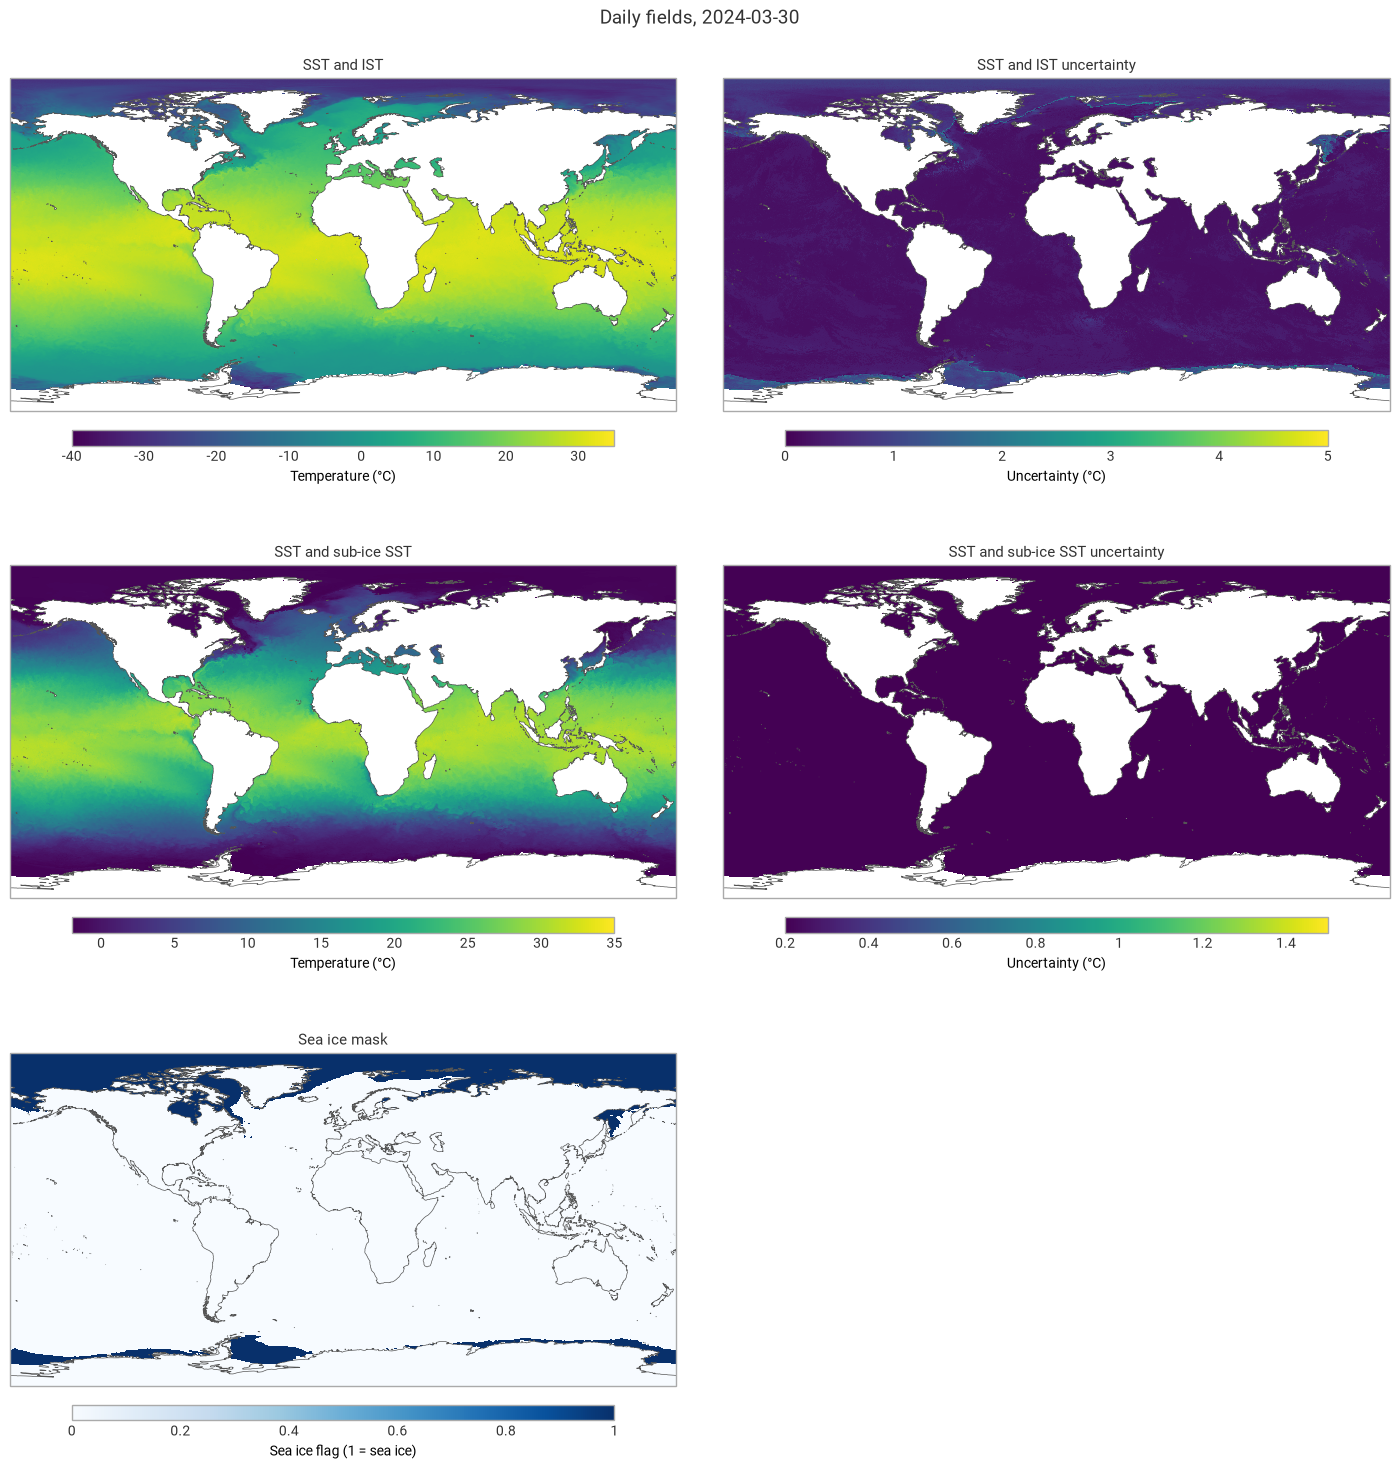

In [9]:
fig = ekp.Figure(rows=3, columns=2, figsize=(14, 14), hspace=0.15, wspace=0.05)
for title, panel in daily_panels.items():
    draw_map(fig.add_map(domain="Global"), title=title, **panel)
fig.title(f"Daily fields, {date_str}")
fig.show()

**Figure 1.** Daily fields for the selected day: the combined sea surface and ice surface temperature and its uncertainty (top row), the sea surface temperature, including the estimated water temperature under the sea ice, and its uncertainty (middle row), and the grid cells flagged as sea ice in the mask (bottom), which are the regions where the ice surface temperature is used in the combined field. The uncertainty of the combined field is largest over the sea ice. Data source: C3S Climate Data Store, [Combined sea surface and sea ice surface temperature data derived from satellite observations](https://doi.org/10.24381/9b0f528b) (Danish Meteorological Institute, DMI).

The basic statistics of each temperature and uncertainty field are collated in a [pandas.DataFrame](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html), with one row per field. The sea ice mask is a flag rather than a physical quantity, so it is not included:

In [10]:
daily_stats = pd.DataFrame(
    {
        f"{title} (°C)": basic_statistics(panel["field"])
        for title, panel in daily_panels.items()
        if title != "Sea ice mask"
    }
).T
daily_stats.round(2)

,Mean,Median,Standard deviation,Maximum,Minimum
SST and IST (°C),10.62,15.44,18.18,34.56,-40.89
SST and IST uncertainty (°C),0.36,0.25,0.26,28.31,0.00
SST and sub-ice SST (°C),14.21,15.44,12.07,34.56,-2.24
SST and sub-ice SST uncertainty (°C),-272.88,-272.90,0.08,-271.50,-273.02


### Calculate the climate normal

Anthropogenic activities and natural variations from years to decades shape the Earth's climate. To evaluate anomalous conditions of a specific month or year, the World Meteorological Organization (WMO) defines `standard reference periods` used to create `climate normals`. `Climate normals` can be considered as the typical climate for the period the normals are based on. Since 2021, the WMO recommends the reference period 1991-2020.

We compute the climate normal of the surface temperature for each calendar month from the monthly files of the CDS. The monthly files are downloaded in bundles of one decade (120 files per request). For each decade, the surface temperature is averaged onto a coarser grid, and the mean of each calendar month is computed with the earthkit-transforms function `climatology.monthly_mean`. As each decade has the same number of years, the climate normal is the mean of the three decadal means.

:::{note}
The full 1991-2020 period requires downloading 360 global monthly files. To try the workflow more quickly, reduce the list of `clim_decades`, e.g. to `[range(2011, 2021)]`.
:::

In [11]:
# Settings defined by user
clim_decades = [range(1991, 2001), range(2001, 2011), range(2011, 2021)]
months = [f"{m:02d}" for m in range(1, 13)]
clim_str = f"{clim_decades[0][0]}-{clim_decades[-1][-1]}"

# Mean of each calendar month, one decade at a time
ds_all = None
for decade in clim_decades:
    print(f"Downloading {decade[0]}-{decade[-1]}")
    eds_decade = ekd.from_source("cds", "satellite-ist-sst-global", sst_request(list(decade), months))
    ds_decade = eds_decade.to_xarray()
    if ds_all is None:
        ds_all = ds_decade
    else:
        ds_all = xr.concat([ds_all, ds_decade], dim="time")
ds_all

<xarray.Dataset> Size: 261GB
Dimensions:                (time: 360, bnds: 2, lat: 3600, lon: 7200)
Coordinates:
  * time                   (time) datetime64[ns] 3kB 1991-01-16T12:00:00 ... ...
  * lat                    (lat) float32 14kB -89.97 -89.92 ... 89.93 89.98
  * lon                    (lon) float32 29kB -180.0 -179.9 ... 179.9 180.0
Dimensions without coordinates: bnds
Data variables:
    time_bnds              (time, bnds) datetime64[ns] 6kB dask.array<chunksize=(1, 2), meta=np.ndarray>
    analysed_st            (time, lat, lon) float32 37GB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
    analysis_error_st      (time, lat, lon) float32 37GB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
    mask                   (time, lat, lon) float32 37GB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
    sea_ice_fraction       (time, lat, lon) float32 37GB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
    analysed_sst           (time, lat, lon) float32 37GB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
    sea_ice_fraction_flag  (time, lat, lon) float32 37GB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
    analysis_error_sst     (time, lat, lon) float32 37GB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
Attributes: (12/48)
    history:                    Version 1.0
    source:                     ESA SST CCI v3.0 and C3S v3.0 L3U, AASTIv2 IS...
    institution:                Danish Meteorological Institute, DMI
    Conventions:                CF-1.4, Unidata Observation Dataset v1.0
    title:                      Global Sea and Ice Surface Temperature, L4, 5...
    summary:                    DMI Sea and Ice Surface Temperature analysis ...
    ...                         ...
    publisher_url:              https://climate.copernicus.eu/
    publisher_email:            https://climate.copernicus.eu/help-and-suppor...
    processing_level:           L4
    cdm_data_type:              grid
    comment:                    IN NO EVENT SHALL DMI OR ITS REPRESENTATIVES ...
    frequency:                  mon

In [12]:
print("Computing climatology...")
st_clim = ekt.climatology.monthly_mean(ds_all["analysed_st"]).compute()
st_clim = convert_dataarray(st_clim, "celsius")
# Display as a dataset
st_clim.to_dataset(name="analysed_st")

Computing climatology...


<xarray.Dataset> Size: 1GB
Dimensions:      (lon: 7200, lat: 3600, month: 12)
Coordinates:
  * lon          (lon) float32 29kB -180.0 -179.9 -179.9 ... 179.9 179.9 180.0
  * lat          (lat) float32 14kB -89.97 -89.92 -89.88 ... 89.88 89.93 89.98
  * month        (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
Data variables:
    analysed_st  (month, lat, lon) float32 1GB nan nan nan ... -30.43 -30.43

To check the climatology, we plot the seasonal cycle of the mean surface temperature over the globe. The earthkit-transforms function `spatial.reduce` computes the mean over latitude and longitude. With `weights="latitude"`, each grid cell is weighted by the cosine of its latitude, as cells near the poles cover a smaller area than cells near the equator:

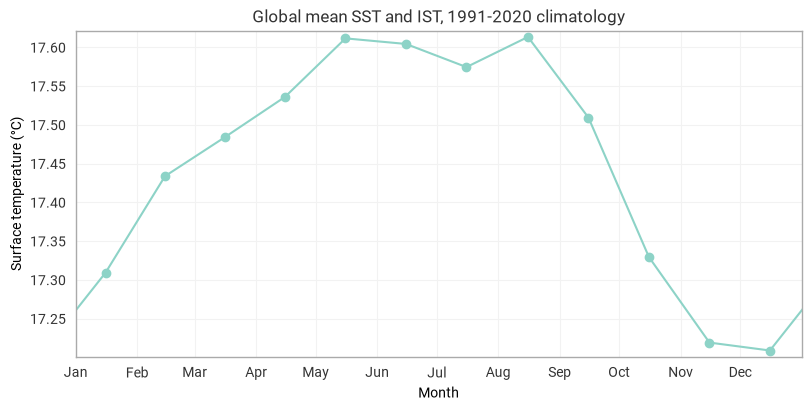

In [13]:
# Calculate global mean SST and IST climatology
st_clim_global = ekt.spatial.reduce(st_clim, weights="latitude")

chart = ekp.Climatology(wrap_time=True)
chart.line(st_clim_global, marker="o")
chart.ax.set_xlabel("Month")
chart.ax.set_ylabel("Surface temperature (°C)")
chart.title(f"Global mean SST and IST, {clim_str} climatology")
chart.show()

**Figure 2.** Seasonal cycle of the global, area-weighted mean combined sea and ice surface temperature in the climatology. Data source: C3S Climate Data Store, [Combined sea surface and sea ice surface temperature data derived from satellite observations](https://doi.org/10.24381/9b0f528b) (Danish Meteorological Institute, DMI).

### Calculate the anomaly of a given year

The term anomaly refers to the deviation of a value from the long-term average. Positive or negative anomalies indicate that the temperatures of a particular year were respectively warmer or cooler than the climate normal.

We download the monthly files of the selected year with earthkit-data, and average them onto the same coarse grid as the climatology. The earthkit-transforms function `climatology.anomaly` subtracts the climatology of the matching calendar month from each monthly field, and `temporal.mean` then averages the 12 monthly anomalies into the annual mean anomaly.

In [14]:
# Settings defined by user
anomaly_year = 2024

eds_anom = ekd.from_source("cds", "satellite-ist-sst-global", sst_request([anomaly_year], months))
ds_anom = eds_anom.to_xarray()
st_2024 = convert_dataarray(ds_anom['analysed_st'], "celsius")
st_anom_monthly = ekt.climatology.anomaly(st_2024, st_clim)
st_anom = ekt.temporal.mean(st_anom_monthly).compute()

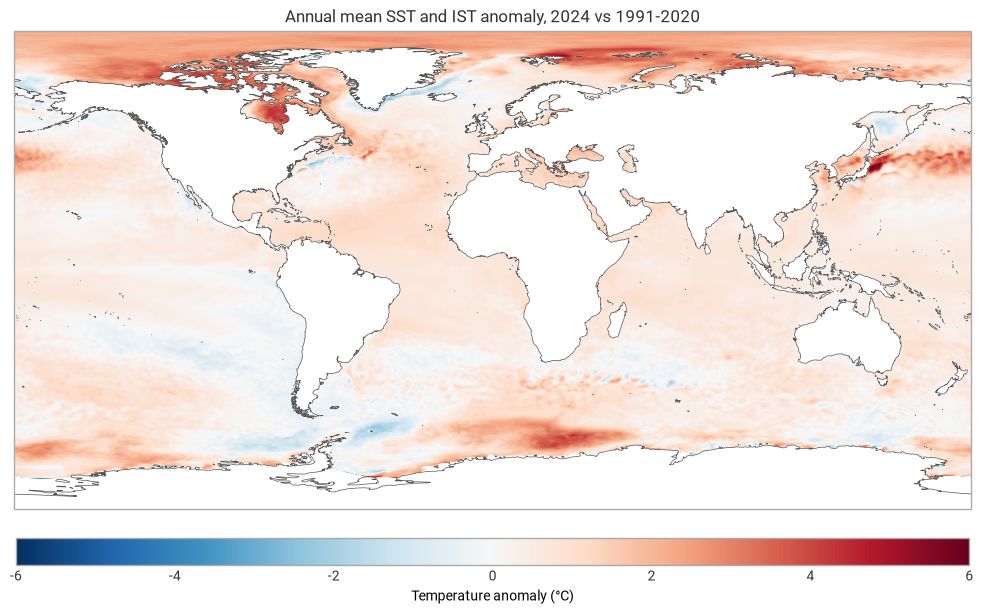

In [15]:
# Plot a single global map of a field
chart = ekp.Map(figsize=(12, 6), domain="Global")
draw_map(
    chart,
    st_anom,
    f"Annual mean SST and IST anomaly, {anomaly_year} vs {clim_str}",
    "Temperature anomaly (°C)",
    cmap="RdBu_r",
    vmin=-6,
    vmax=6,
)
chart.show()

**Figure 3.** Annual mean anomaly of the combined sea and ice surface temperature for the selected year, with respect to the climatology. Red colours show where the year was warmer than the climate normal, and blue colours where it was cooler. Data source: C3S Climate Data Store, [Combined sea surface and sea ice surface temperature data derived from satellite observations](https://doi.org/10.24381/9b0f528b) (Danish Meteorological Institute, DMI).

### Regional statistics of the anomaly

To summarise the anomaly, we compute its area-weighted mean and its standard deviation for the whole globe, for the northern third (north of 30°N) and for the southern third (south of 30°S), with the earthkit-transforms function `spatial.reduce`.

The regions are defined as longitude/latitude boxes (polygons) in a [GeoDataFrame](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.html). You can add or change regions, e.g. to a smaller box around the Arctic Ocean, or replace them by any other polygons, such as ocean basins read from a shapefile with `gpd.read_file`.

In [16]:
# Settings defined by user: regions as longitude/latitude boxes
# box(west, south, east, north)
regions = gpd.GeoDataFrame(
    {
        "region": [
            "Full globe",
            "Northern third (north of 30°N)",
            "Southern third (south of 30°S)",
        ]
    },
    geometry=[
        box(-180, -90, 180, 90),
        box(-180, 30, 180, 90),
        box(-180, -90, 180, -30),
    ],
    crs="EPSG:4326",
).set_index("region")
regions

,geometry
region,
Full globe,"POLYGON ((180 -90, 180 90, -180 90, -180 -90, ..."
Northern third (north of 30°N),"POLYGON ((180 30, 180 90, -180 90, -180 30, 18..."
Southern third (south of 30°S),"POLYGON ((180 -90, 180 -30, -180 -30, -180 -90..."


Outliers, here defined as values more than 3 times the [median absolute deviation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.median_abs_deviation.html) from the median, are excluded first. `spatial.reduce` then masks the anomaly with each polygon (a grid cell is included if its centre is inside the polygon) and reduces it over latitude and longitude, returning one value per region along the `region` dimension. The mean and standard deviation of each region are then collated in a [pandas.DataFrame](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html):

In [17]:
# Exclude outliers, more than 3 median absolute deviations from the median
med = st_anom.median()
mad = abs(st_anom - med).median()
st_anom_filtered = st_anom.where(abs(st_anom - med) < 3 * mad)

# Area-weighted mean and standard deviation in each region
mean = ekt.spatial.reduce(st_anom_filtered, regions, weights="latitude")
std = ekt.spatial.reduce(st_anom_filtered, regions, how="std")

# Collate the regional statistics in a table, one row per region
anom_stats = pd.DataFrame(
    {
        "Mean anomaly (°C)": mean.to_series(),
        "Standard deviation (°C)": std.to_series(),
    }
)
anom_stats.round(2)

,Mean anomaly (°C),Standard deviation (°C)
region,,
Full globe,0.50,0.43
Northern third (north of 30°N),0.67,0.51
Southern third (south of 30°S),0.42,0.49


## Take home messages 📌

- Daily and monthly gap-free maps of the combined sea and ice surface temperature from 1982 onwards are available from the C3S Climate Data Store, as a Climate Data Record (CDR) that is extended by an Interim CDR (ICDR).
- The ice surface temperature over sea ice can be tens of degrees colder than the sea surface temperature, and has a larger uncertainty.
- Annual anomalies for 2024 compared to the 1991-2020 climatology are most pronounced at high latitudes of the Northern and Southern Hemispheres (particularly in the sea-ice covered regions of the Arctic), and in very dynamic ocean regions such as the Kuroshio current (east of Japan) and parts of the warm "blob" in the North Pacific (off the west coast of North America).
- The large anomalies in the Arctic are consistent with Arctic amplification, which leads to a much larger temperature increase in the Arctic than in the rest of the world.
- Slightly negative anomalies are found near the ice edge in the Fram Strait, the passage between Greenland and Svalbard.

## References

**Datasets**
- Copernicus Climate Change Service (C3S). Combined sea surface and sea ice surface temperature data derived from satellite observations. Copernicus Climate Change Service (C3S) Climate Data Store (CDS). DOI: [10.24381/9b0f528b](https://doi.org/10.24381/9b0f528b)

**Publications**
- Nielsen-Englyst, P., Høyer, J. L., Kolbe, W. M., Dybkjær, G., Lavergne, T., Tonboe, R. T., Skarpalezos, S., and Karagali, I. (2023). A combined sea and sea-ice surface temperature climate dataset of the Arctic, 1982-2021. Remote Sensing of Environment, 284, 113331. DOI: [10.1016/j.rse.2022.113331](https://doi.org/10.1016/j.rse.2022.113331)

**More information**
- [Product user guide and specification](https://dast.copernicus-climate.eu/documents/satellite-ist-sst-global/WP2-FDDP-SSTv1.0-PUGS-v1.1_Final-2.pdf)
- [Documentation of the CDS dataset](https://cds.climate.copernicus.eu/datasets/satellite-ist-sst-global?tab=documentation)
- [WMO guidelines on the calculation of climate normals](https://library.wmo.int/idurl/4/55797)

## Glossary

- **SST** - Sea Surface Temperature: the temperature of the ocean water close to the surface.
- **IST** - Ice Surface Temperature: the skin temperature of the surface of the sea ice.
- **Climatology / climate normal** - The average conditions over a long reference period, typically 30 years (here 1991-2020).
- **Anomaly** - The difference between a value and the climatology.
- **CDR** - Climate Data Record: a time series of measurements of sufficient length, consistency and continuity to determine climate variability and change.
- **ICDR** - Interim Climate Data Record: an extension of a CDR, forward-processed with the same algorithm and processing environment as the CDR, but whose consistency and continuity with the CDR have not yet been fully verified.
- **Level 4 (L4)** - Gap-free fields, where satellite observations are combined and interpolated onto a regular grid.